# Этап 7. Сколько бригад нужно в жару (H4)

**Гипотеза H4:** через теорию очередей (формула Erlang C) прогноз вызовов можно перевести в число бригад, нужных, чтобы время ожидания не ухудшалось.

### Теория очередей за одну минуту
Представь кассы в магазине:
- **λ (лямбда)** — сколько покупателей приходит в час (у нас — вызовов в час);
- **S** — сколько времени касса занята одним покупателем (у нас — сколько часов бригада занята вызовом: доезд, помощь, госпиталь, возвращение);
- **A = λ × S** — **нагрузка** в «эрлангах»: сколько бригад в среднем заняты одновременно. Если приходит 60 вызовов в час и каждый занимает бригаду на 1,2 часа, то одновременно заняты ~72 бригады;
- **N** — сколько бригад на смене. Нужно N > A, иначе очередь растёт бесконечно.

**Erlang C** отвечает: при N бригадах и нагрузке A какова вероятность, что вызов **ждёт** свободную бригаду дольше t?

Главное свойство: когда N близко к A, ожидание растёт **взрывообразно**. Это та самая нелинейность из H2.

### Что измеряем в данных
- **Ожидание** = от регистрации вызова до назначения бригады (`first_assignment_datetime − incident_datetime`). Это и есть «очередь»: вызов ждёт, пока освободится бригада.
- **Занятость S** = от назначения бригады до закрытия вызова.
- **Цель:** доля вызовов, ждущих бригаду **дольше 1 минуты**, не должна расти в жару.

### Ограничение
Реального числа бригад на смене в открытых данных **нет**. Поэтому мы оцениваем **«эффективное» число бригад**: сколько бригад в модели Erlang C дают такое же ожидание, как в реальности. Ответ — не «в Бруклине 84 машины», а «в жару нужно **на столько-то больше**, чем в обычный день».

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb

## 1. Данные: пиковые часы летом 2025–2026

Берём июнь–август 2025 и 2026 (самые свежие, штат бригад похож на нынешний) и часы 10:00–19:59, когда вызовов больше всего. Для каждого часа в каждом районе считаем: число вызовов, среднюю занятость бригады и долю вызовов, ждавших дольше 60 секунд.

Занятость берём от 1 минуты до 6 часов: короче — ошибки, дольше — забытые незакрытые вызовы.

In [2]:
con = duckdb.connect()
hourly = con.sql("""
SELECT CAST(incident_datetime AS DATE) AS date,
       hour(incident_datetime)          AS hour,
       borough,
       count(*) AS n_calls,
       avg(epoch(incident_close_datetime - first_assignment_datetime) / 3600)
           FILTER (WHERE epoch(incident_close_datetime - first_assignment_datetime) BETWEEN 60 AND 6*3600) AS busy_h,
       avg((epoch(first_assignment_datetime - incident_datetime) > 60)::int) AS share_wait60
FROM '../data/raw/ems/202[5-6]-0[6-8].parquet'
WHERE initial_call_type != 'STNDBY' AND borough != 'UNKNOWN'
GROUP BY ALL
""").df()
hourly["date"] = pd.to_datetime(hourly["date"])

weather = pd.read_parquet("../data/processed/daily_borough.parquet")[["date", "borough", "temperature_2m_max"]]
hourly = hourly.merge(weather, on=["date", "borough"])
peak = hourly[hourly["hour"].between(10, 19)].copy()
peak["weather"] = pd.cut(peak["temperature_2m_max"], [-50, 30, 33, 50], labels=["обычный (<30 °C)", "тёплый (30–33)", "жара (33+ °C)"])

In [3]:
tab = (peak.groupby(["borough", "weather"], observed=True)
            .agg(days=("date", "nunique"),
                 calls_per_hour=("n_calls", "mean"),
                 busy_hours=("busy_h", "mean"),
                 share_wait60=("share_wait60", "mean")))
tab["load_A"] = tab["calls_per_hour"] * tab["busy_hours"]
tab.round(2)

days  calls_per_hour  busy_hours  \
borough                  weather                                              
BRONX                    обычный (<30 °C)   112           53.85        1.28   
                         тёплый (30–33)      45           56.48        1.25   
                         жара (33+ °C)       27           58.72        1.25   
BROOKLYN                 обычный (<30 °C)   125           62.50        1.22   
                         тёплый (30–33)      39           66.58        1.22   
                         жара (33+ °C)       20           71.52        1.22   
MANHATTAN                обычный (<30 °C)   114           55.50        1.15   
                         тёплый (30–33)      42           60.10        1.14   
                         жара (33+ °C)       28           62.82        1.15   
QUEENS                   обычный (<30 °C)   122           46.64        1.24   
                         тёплый (30–33)      39           48.53        1.23   
                         жара (33+ °C)       23           54.05        1.23   
RICHMOND / STATEN ISLAND обычный (<30 °C)   121           10.09        1.12   
                         тёплый (30–33)      35           10.33        1.12   
                         жара (33+ °C)       28           11.12        1.13   

                                           share_wait60  load_A  
borough                  weather                                 
BRONX                    обычный (<30 °C)          0.55   68.68  
                         тёплый (30–33)            0.56   70.74  
                         жара (33+ °C)             0.58   73.43  
BROOKLYN                 обычный (<30 °C)          0.30   76.47  
                         тёплый (30–33)            0.35   81.32  
                         жара (33+ °C)             0.42   87.13  
MANHATTAN                обычный (<30 °C)          0.43   63.95  
                         тёплый (30–33)            0.47   68.73  
                         жара (33+ °C)             0.48   72.15  
QUEENS                   обычный (<30 °C)          0.37   57.64  
                         тёплый (30–33)            0.39   59.49  
                         жара (33+ °C)             0.49   66.43  
RICHMOND / STATEN ISLAND обычный (<30 °C)          0.18   11.30  
                         тёплый (30–33)            0.18   11.57  
                         жара (33+ °C)             0.25   12.52

**Как читать:**
- В жару вызовов в час больше (Бруклин: 62 → 72), а **занятость бригады на вызов почти не меняется** (~1,2 часа). Значит, нагрузка A растёт только за счёт числа вызовов.
- Доля вызовов, ждущих бригаду дольше минуты, в жару растёт во всех районах. В Бронксе даже в обычный день больше половины вызовов ждёт: район работает на пределе.

## 2. Формула Erlang C

Считаем через формулу Erlang B (вероятность, что все заняты, в системе без очереди), её удобно считать по шагам без огромных факториалов:

$$B_0 = 1, \quad B_k = \frac{A \cdot B_{k-1}}{k + A \cdot B_{k-1}}$$

Потом переводим в Erlang C (вероятность **ждать вообще**):
$$C = \frac{N \cdot B_N}{N - A(1 - B_N)}$$

И вероятность ждать **дольше t**:
$$P(\text{ожидание} > t) = C \cdot e^{-(N - A)\, t / S}$$

In [4]:
def erlang_c(N, A):
    """Вероятность, что вызов ждёт: N бригад, нагрузка A эрлангов."""
    if N <= A:
        return 1.0                     # бригад меньше нагрузки: очередь растёт бесконечно
    B = 1.0
    for k in range(1, N + 1):
        B = A * B / (k + A * B)        # Erlang B по шагам
    return N * B / (N - A * (1 - B))

def p_wait_longer(N, A, S, t_hours):
    """Доля вызовов, ждущих бригаду дольше t."""
    if N <= A:
        return 1.0
    return erlang_c(N, A) * np.exp(-(N - A) * t_hours / S)

def units_needed(A, S, target, t_hours=60/3600):
    """Минимальное число бригад, при котором доля ждущих дольше t не выше target."""
    N = int(A) + 1
    while p_wait_longer(N, A, S, t_hours) > target:
        N += 1
    return N

### Обрыв: как ожидание зависит от числа бригад (Бруклин)

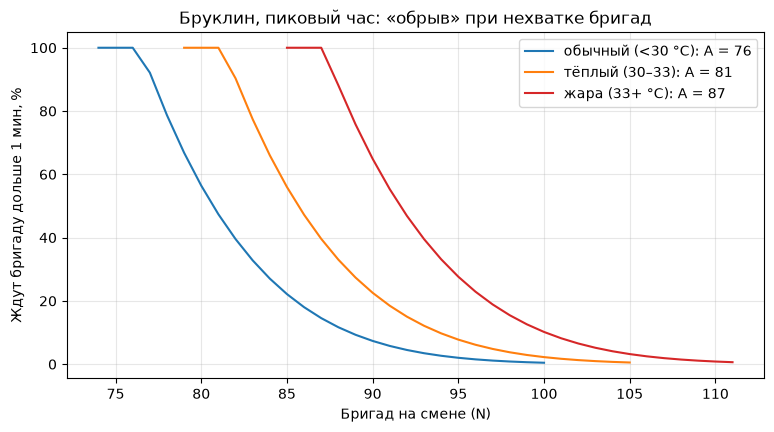

In [5]:
b = tab.loc["BROOKLYN"]
plt.figure(figsize=(9, 4.5))
for w, color in zip(b.index, ["tab:blue", "tab:orange", "tab:red"]):
    A, S = b.loc[w, "load_A"], b.loc[w, "busy_hours"]
    Ns = np.arange(int(A) - 2, int(A) + 25)
    plt.plot(Ns, [p_wait_longer(N, A, S, 60/3600) * 100 for N in Ns], color=color, label=f"{w}: A = {A:.0f}")
plt.xlabel("Бригад на смене (N)")
plt.ylabel("Ждут бригаду дольше 1 мин, %")
plt.title("Бруклин, пиковый час: «обрыв» при нехватке бригад")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Как читать:** каждая кривая — свой тип дня. Если идти справа налево (убирать бригады), доля ждущих сначала почти не меняется, а потом **резко** уходит к 100 %. Жаркая (красная) кривая сдвинута вправо на ~10 бригад: при том же штате система в жару оказывается гораздо ближе к обрыву.

## 3. Калибровка: сколько «эффективных» бригад работает

Для каждого района и типа дня находим N, при котором Erlang C даёт **ту же** долю ждущих, что в реальности. Это и есть «эффективное» число бригад.

Потом спрашиваем: сколько бригад **нужно** в жару, чтобы ожидание было как в обычный день?

In [6]:
rows = []
for borough in tab.index.get_level_values(0).unique():
    normal = tab.loc[(borough, "обычный (<30 °C)")]
    hot    = tab.loc[(borough, "жара (33+ °C)")]
    rows.append({
        "район": borough,
        "N обычный день":    units_needed(normal["load_A"], normal["busy_hours"], normal["share_wait60"]),
        "N жара, по факту":  units_needed(hot["load_A"],    hot["busy_hours"],    hot["share_wait60"]),
        "N жара, нужно":     units_needed(hot["load_A"],    hot["busy_hours"],    normal["share_wait60"]),
        # сценарии «+5 °C»: из этапа 4 (+4,2 % вызовов) и при пороге 28 °C (+7,5 %)
        "N жара +5 °C (мин)":  units_needed(hot["load_A"] * 1.042, hot["busy_hours"], normal["share_wait60"]),
        "N жара +5 °C (макс)": units_needed(hot["load_A"] * 1.075, hot["busy_hours"], normal["share_wait60"]),
    })
units = pd.DataFrame(rows).set_index("район")
units.loc["ВЕСЬ ГОРОД"] = units.sum()
units

,N обычный день,"N жара, по факту","N жара, нужно",N жара +5 °C (мин),N жара +5 °C (макс)
район,,,,,
BRONX,73,77,78,81,83
BROOKLYN,84,93,95,99,102
MANHATTAN,69,77,78,81,83
QUEENS,63,71,72,75,78
RICHMOND / STATEN ISLAND,16,17,17,18,18
ВЕСЬ ГОРОД,305,335,340,354,364


In [7]:
base = units["N обычный день"]
delta = pd.DataFrame({
    "жара: город добавил":      units["N жара, по факту"] - base,
    "жара: нужно добавить":     units["N жара, нужно"] - base,
    "жара +5 °C: нужно (мин)":  units["N жара +5 °C (мин)"] - base,
    "жара +5 °C: нужно (макс)": units["N жара +5 °C (макс)"] - base,
})
delta_pct = (delta.div(base, axis=0) * 100).round(0).astype(int).astype(str) + " %"
delta.astype(str) + " (" + delta_pct + ")"


,жара: город добавил,жара: нужно добавить,жара +5 °C: нужно (мин),жара +5 °C: нужно (макс)
район,,,,
BRONX,4 (5 %),5 (7 %),8 (11 %),10 (14 %)
BROOKLYN,9 (11 %),11 (13 %),15 (18 %),18 (21 %)
MANHATTAN,8 (12 %),9 (13 %),12 (17 %),14 (20 %)
QUEENS,8 (13 %),9 (14 %),12 (19 %),15 (24 %)
RICHMOND / STATEN ISLAND,1 (6 %),1 (6 %),2 (12 %),2 (12 %)
ВЕСЬ ГОРОД,30 (10 %),35 (11 %),49 (16 %),59 (19 %)


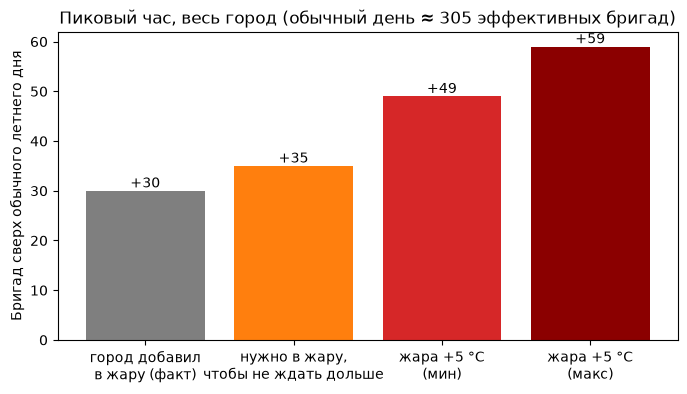

In [8]:
city = delta.loc["ВЕСЬ ГОРОД"]
plt.figure(figsize=(8, 4))
bars = plt.bar(["город добавил\nв жару (факт)", "нужно в жару,\nчтобы не ждать дольше",
                "жара +5 °C\n(мин)", "жара +5 °C\n(макс)"],
               city.values, color=["tab:grey", "tab:orange", "tab:red", "darkred"])
plt.bar_label(bars, labels=[f"+{v:.0f}" for v in city.values])
plt.ylabel("Бригад сверх обычного летнего дня")
plt.title(f"Пиковый час, весь город (обычный день ≈ {base['ВЕСЬ ГОРОД']:.0f} эффективных бригад)")
plt.show()

## Итоги: подтвердилась ли H4?

1. **Да, перевод работает.** Erlang C связывает три вещи: число вызовов, занятость бригады и ожидание. Зная прогноз вызовов на завтра (этап 5), можно заранее посчитать, сколько бригад поставить на смену.
2. **Система в жару как-то компенсирует нагрузку.** Если бы число бригад не менялось, в дни 33+ °C модель предсказывает почти полный обвал (в Бруклине ждали бы почти все вызовы). В реальности ожидание выросло умеренно: это соответствует **~+30 эффективным бригадам (+10 %)** в пиковый час. Чем именно (дополнительные смены, переброски, отложенные несрочные вызовы), по открытым данным проверить нельзя: официальный NYC Heat Emergency Plan о дополнительных сменах скорой не сообщает.
3. **Но этой компенсации не хватает:** чтобы ожидание в жару было как в обычный день, нужно **~+35 бригад (+11–12 %)**. Недобор всего ~5 бригад на город, но из-за «обрыва» его хватает, чтобы доля ждущих дольше минуты выросла с 30 % до 42 % (Бруклин).
4. **Сценарий «+5 °C»** (волна жары сильнее июньской 2025): нужно **+49…+59 бригад (+16…19 %)** сверх обычного летнего дня.
5. Вывод для планирования: при прогнозе 33 °C+ закладывать **+12 %** бригад в пиковые часы, при экстремальной жаре **+16–19 %**.

**Ограничения:**
- Erlang C предполагает, что все бригады одинаковые, вызовы приходят случайно, а очередь общая. В реальности есть приоритеты (срочные первыми), бригады двух типов (BLS/ALS) и переброски между районами.
- «Эффективные» бригады — не реальные машины, а модельный эквивалент. Сравнивать можно **разницу**, а не абсолютные числа.
- Средние по пиковым часам сглаживают самые тяжёлые часы; в них недобор больше.
- Около обрыва модель очень чувствительна: ±1–2 бригады — в пределах погрешности.
- Мы считаем каждый пиковый час как стационарный; при быстро меняющемся потоке такой подход может занижать нужный штат (Green, Kolesar & Whitt, 2007).

**Строка для README:** *Модель массового обслуживания (Erlang C), откалиброванная по фактическому времени назначения бригад, показывает: в дни 33 °C+ для сохранения обычного времени ожидания нужно +11–12 % бригад в пиковые часы (фактически система компенсирует ~+10 %); при волне жары на 5 °C сильнее — +16–19 %.*